In [1]:
!pip install pandas numpy matplotlib seaborn scikit-learn nltk tensorflow wordcloud


[notice] A new release of pip is available: 26.0.1 -> 26.1.2
[notice] To update, run: pip install --upgrade pip


In [160]:
# Basic libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import zipfile
import os
import re
import time

# NLTK libraries
import nltk
from nltk.corpus import stopwords
from nltk.stem import PorterStemmer
from nltk.sentiment.vader import SentimentIntensityAnalyzer
from sklearn.preprocessing import label_binarize
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression

# Machine learning utilities
from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix,
    roc_curve,
    auc
)

# Deep learning libraries
import tensorflow as tf
from tensorflow.keras.preprocessing.text import Tokenizer
from tensorflow.keras.preprocessing.sequence import pad_sequences
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import (
    Embedding,
    LSTM,
    GRU,
    Dense,
    Dropout,
    Bidirectional
)
from tensorflow.keras.callbacks import EarlyStopping

# Word cloud
from wordcloud import WordCloud

In [3]:
#Downloads required NLTK resources: English stopwords and the VADER sentiment lexicon.
nltk.download('stopwords')
nltk.download('vader_lexicon')

[nltk_data] Downloading package stopwords to
[nltk_data]     /Users/nishan/nltk_data...
[nltk_data]   Package stopwords is already up-to-date!
[nltk_data] Downloading package vader_lexicon to
[nltk_data]     /Users/nishan/nltk_data...
[nltk_data]   Package vader_lexicon is already up-to-date!


True

In [4]:
import os

folder_path = "drug_reviews_data/drugs_reviews"

train_path = "drug_reviews_data/drugs_reviews/drugsComTrain_raw.csv"
test_path = "drug_reviews_data/drugs_reviews/drugsComTest_raw.csv"

train_df = pd.read_csv(train_path)
test_df = pd.read_csv(test_path)

print("Train shape:", train_df.shape)
print("Test shape:", test_df.shape)

train_df.head()

Train shape: (161297, 7)
Test shape: (53766, 7)


,uniqueID,drugName,condition,review,rating,date,usefulCount
0,206461,Valsartan,Left Ventricular Dysfunction,"""It has no side effect, I take it in combinati...",9,20-May-12,27
1,95260,Guanfacine,ADHD,"""My son is halfway through his fourth week of ...",8,27-Apr-10,192
2,92703,Lybrel,Birth Control,"""I used to take another oral contraceptive, wh...",5,14-Dec-09,17
3,138000,Ortho Evra,Birth Control,"""This is my first time using any form of birth...",8,3-Nov-15,10
4,35696,Buprenorphine / naloxone,Opiate Dependence,"""Suboxone has completely turned my life around...",9,27-Nov-16,37


In [5]:
train_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 161297 entries, 0 to 161296
Data columns (total 7 columns):
 #   Column       Non-Null Count   Dtype 
---  ------       --------------   ----- 
 0   uniqueID     161297 non-null  int64 
 1   drugName     161297 non-null  object
 2   condition    160398 non-null  object
 3   review       161297 non-null  object
 4   rating       161297 non-null  int64 
 5   date         161297 non-null  object
 6   usefulCount  161297 non-null  int64 
dtypes: int64(3), object(4)
memory usage: 8.6+ MB


In [6]:
train_df.isnull().sum()

uniqueID         0
drugName         0
condition      899
review           0
rating           0
date             0
usefulCount      0
dtype: int64

In [7]:
# Keep only required columns 
train_df = train_df[['uniqueID', 'drugName', 'condition', 'review', 'rating', 'date', 'usefulCount']]

# Remove missing reviews/ratings
train_df = train_df.dropna(subset=['review', 'rating'])

print("Cleaned dataset shape:",train_df.shape)
train_df.head()

Cleaned dataset shape: (161297, 7)


,uniqueID,drugName,condition,review,rating,date,usefulCount
0,206461,Valsartan,Left Ventricular Dysfunction,"""It has no side effect, I take it in combinati...",9,20-May-12,27
1,95260,Guanfacine,ADHD,"""My son is halfway through his fourth week of ...",8,27-Apr-10,192
2,92703,Lybrel,Birth Control,"""I used to take another oral contraceptive, wh...",5,14-Dec-09,17
3,138000,Ortho Evra,Birth Control,"""This is my first time using any form of birth...",8,3-Nov-15,10
4,35696,Buprenorphine / naloxone,Opiate Dependence,"""Suboxone has completely turned my life around...",9,27-Nov-16,37


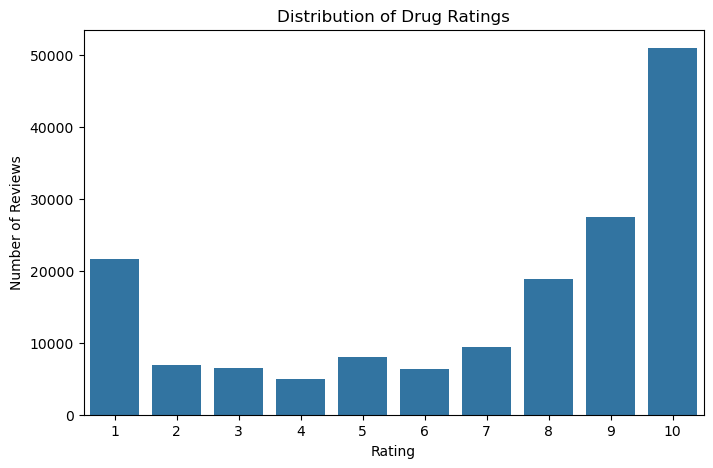

In [8]:
plt.figure(figsize=(8,5))
sns.countplot(x='rating', data=train_df)
plt.title("Distribution of Drug Ratings")
plt.xlabel("Rating")
plt.ylabel("Number of Reviews")
plt.show()

In [9]:
train_df = train_df.dropna(subset=['review','rating'])

test_df = test_df.dropna(subset=['review','rating'])

In [10]:
#numerical ratings into sentiment classes
def rating_to_sentiment(rating):
    if rating <= 4:
        return 0   # Negative
    elif rating <= 6:
        return 1   # Neutral
    else:
        return 2   # Positive

train_df['sentiment'] = train_df['rating'].apply(rating_to_sentiment)
test_df['sentiment'] = test_df['rating'].apply(rating_to_sentiment)

train_df[['rating', 'sentiment']].head()

,rating,sentiment
0,9,2
1,8,2
2,5,1
3,8,2
4,9,2


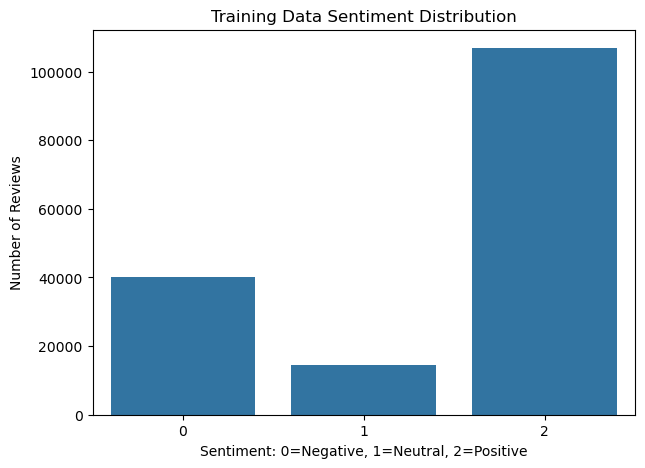

In [11]:
plt.figure(figsize=(7,5))
sns.countplot(x='sentiment', data=train_df)
plt.title("Training Data Sentiment Distribution")
plt.xlabel("Sentiment: 0=Negative, 1=Neutral, 2=Positive")
plt.ylabel("Number of Reviews")
plt.show()

In [12]:
stop_words = set(stopwords.words('english'))
stemmer = PorterStemmer()

def clean_text(text):
    text = str(text).lower()
    text = re.sub(r'<.*?>', ' ', text)
    text = re.sub(r'[^a-zA-Z]', ' ', text)
    words = text.split()
    words = [stemmer.stem(word) for word in words if word not in stop_words]
    return " ".join(words)

train_df['clean_review'] = train_df['review'].apply(clean_text)
test_df['clean_review'] = test_df['review'].apply(clean_text)

train_df[['review', 'clean_review']].head()

,review,clean_review
0,"""It has no side effect, I take it in combinati...",side effect take combin bystol mg fish oil
1,"""My son is halfway through his fourth week of ...",son halfway fourth week intuniv becam concern ...
2,"""I used to take another oral contraceptive, wh...",use take anoth oral contracept pill cycl happi...
3,"""This is my first time using any form of birth...",first time use form birth control glad went pa...
4,"""Suboxone has completely turned my life around...",suboxon complet turn life around feel healthie...


In [13]:
def clean_text_for_dl(text):
    text = str(text).lower()
    text = re.sub(r'<.*?>', ' ', text)
    text = re.sub(r'[^a-zA-Z\s]', ' ', text)
    text = re.sub(r'\s+', ' ', text).strip()
    return text

train_df['clean_review_dl'] = train_df['review'].apply(clean_text_for_dl)
test_df['clean_review_dl'] = test_df['review'].apply(clean_text_for_dl)

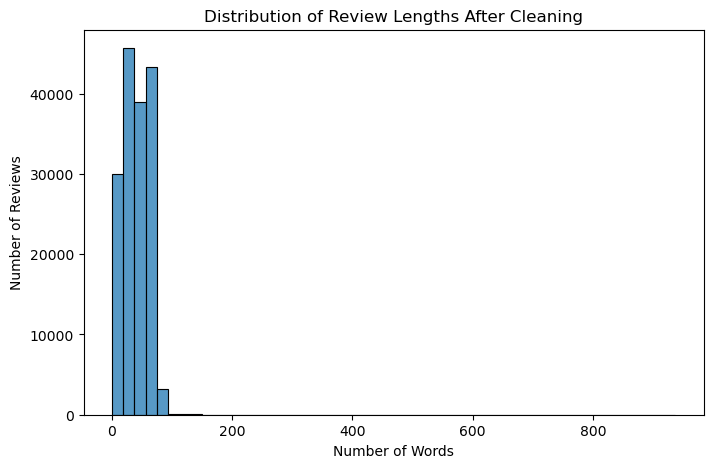

count    161297.000000
mean         40.404198
std          21.595798
min           0.000000
25%          23.000000
50%          40.000000
75%          59.000000
max         937.000000
Name: review_length, dtype: float64

In [14]:
train_df['review_length'] = train_df['clean_review'].apply(lambda x: len(x.split()))

plt.figure(figsize=(8,5))
sns.histplot(train_df['review_length'], bins=50)
plt.title("Distribution of Review Lengths After Cleaning")
plt.xlabel("Number of Words")
plt.ylabel("Number of Reviews")
plt.show()

train_df['review_length'].describe()

In [15]:
# Initialize VADER sentiment analyser
vader = SentimentIntensityAnalyzer()

def vader_sentiment(text):
    score = vader.polarity_scores(str(text))['compound']
    
    if score <= -0.05:
        return 0   # Negative
    elif score >= 0.05:
        return 2   # Positive
    else:
        return 1   # Neutral


In [16]:
test_df['vader_prediction'] = test_df['review'].apply(vader_sentiment)

test_df[['review', 'rating', 'sentiment', 'vader_prediction']].head()

,review,rating,sentiment,vader_prediction
0,"""I&#039;ve tried a few antidepressants over th...",10,2,0
1,"""My son has Crohn&#039;s disease and has done ...",8,2,2
2,"""Quick reduction of symptoms""",9,2,1
3,"""Contrave combines drugs that were used for al...",9,2,2
4,"""I have been on this birth control for one cyc...",9,2,2


In [17]:
vader_accuracy = accuracy_score(test_df['sentiment'], test_df['vader_prediction'])
vader_precision = precision_score(test_df['sentiment'], test_df['vader_prediction'], average='weighted')
vader_recall = recall_score(test_df['sentiment'], test_df['vader_prediction'], average='weighted')
vader_f1 = f1_score(test_df['sentiment'], test_df['vader_prediction'], average='weighted')

print("VADER Accuracy:", vader_accuracy)
print("VADER Precision:", vader_precision)
print("VADER Recall:", vader_recall)
print("VADER F1-score:", vader_f1)

VADER Accuracy: 0.5444704832049995
VADER Precision: 0.6237477532372914
VADER Recall: 0.5444704832049995
VADER F1-score: 0.5529652042062315


In [18]:
print(classification_report(
    test_df['sentiment'],
    test_df['vader_prediction'],
    target_names=['Negative', 'Neutral', 'Positive']
))

              precision    recall  f1-score   support

    Negative       0.36      0.72      0.48     13497
     Neutral       0.08      0.04      0.05      4829
    Positive       0.80      0.55      0.65     35440

    accuracy                           0.54     53766
   macro avg       0.41      0.44      0.39     53766
weighted avg       0.62      0.54      0.55     53766



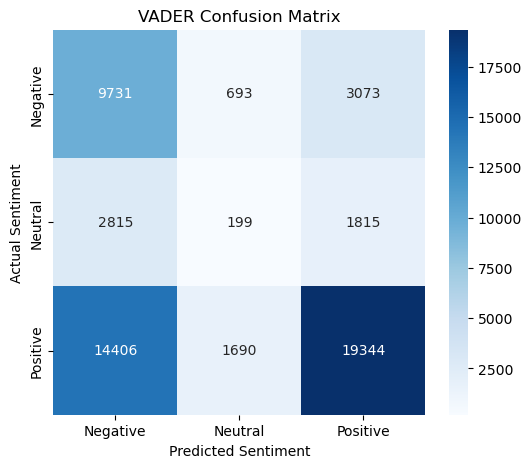

In [19]:
cm_vader = confusion_matrix(test_df['sentiment'], test_df['vader_prediction'])

plt.figure(figsize=(6,5))
sns.heatmap(
    cm_vader,
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=['Negative', 'Neutral', 'Positive'],
    yticklabels=['Negative', 'Neutral', 'Positive']
)

plt.title("VADER Confusion Matrix")
plt.xlabel("Predicted Sentiment")
plt.ylabel("Actual Sentiment")
plt.show()

In [20]:
results = []

results.append({
    'Model': 'VADER',
    'Accuracy': vader_accuracy,
    'Precision': vader_precision,
    'Recall': vader_recall,
    'F1-score': vader_f1,
    'Training Time (seconds)': 0
})

results

[{'Model': 'VADER',
  'Accuracy': 0.5444704832049995,
  'Precision': 0.6237477532372914,
  'Recall': 0.5444704832049995,
  'F1-score': 0.5529652042062315,
  'Training Time (seconds)': 0}]

In [21]:
X_train_text = train_df['clean_review_dl']
X_test_text = test_df['clean_review_dl']

y_train = train_df['sentiment']
y_test = test_df['sentiment']

print("Training samples:", X_train_text.shape)
print("Testing samples:", X_test_text.shape)

Training samples: (161297,)
Testing samples: (53766,)


In [141]:
# Binarize labels for multiclass ROC
y_test_bin = label_binarize(y_test, classes=[0, 1, 2])

n_classes = y_test_bin.shape[1]

In [22]:
from sklearn.utils.class_weight import compute_class_weight

classes = np.unique(y_train)

class_weights_array = compute_class_weight(
    class_weight='balanced',
    classes=classes,
    y=y_train
)

class_weights = dict(zip(classes, class_weights_array))

print("Class Weights:")
print(class_weights)

Class Weights:
{np.int64(0): np.float64(1.3416261176959867), np.int64(1): np.float64(3.745170428160119), np.int64(2): np.float64(0.5031129327070037)}


In [23]:
max_words = 20000
max_len = 200

tokenizer = Tokenizer(num_words=max_words, oov_token="<OOV>")

# Fit tokenizer only on training data to avoid data leakage
tokenizer.fit_on_texts(X_train_text)

X_train_seq = tokenizer.texts_to_sequences(X_train_text)
X_test_seq = tokenizer.texts_to_sequences(X_test_text)

X_train_pad = pad_sequences(
    X_train_seq,
    maxlen=max_len,
    padding='pre',
    truncating='pre'
)

X_test_pad = pad_sequences(
    X_test_seq,
    maxlen=max_len,
    padding='pre',
    truncating='pre'
)

print("X_train_pad shape:", X_train_pad.shape)
print("X_test_pad shape:", X_test_pad.shape)

X_train_pad shape: (161297, 200)
X_test_pad shape: (53766, 200)


In [24]:
from tensorflow.keras.layers import Input

lstm_model = Sequential()

lstm_model.add(Input(shape=(max_len,)))

lstm_model.add(Embedding(
    input_dim=max_words,
    output_dim=128,
    mask_zero=True
))

lstm_model.add(LSTM(
    units=64,
    return_sequences=False
))

lstm_model.add(Dropout(0.5))

lstm_model.add(Dense(64, activation='relu'))

lstm_model.add(Dropout(0.3))

lstm_model.add(Dense(3, activation='softmax'))

lstm_model.compile(
    optimizer='adam',
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

lstm_model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding (Embedding)           │ (None, 200, 128)       │     2,560,000 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm (LSTM)                     │ (None, 64)             │        49,408 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 64)             │         4,160 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 3)              │           195 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,613,763 (9.97 MB)

 Trainable params: 2,613,763 (9.97 MB)

 Non-trainable params: 0 (0.00 B)

In [25]:
early_stop = EarlyStopping(
    monitor='val_loss',
    patience=2,
    restore_best_weights=True
)

start_time = time.time()

lstm_history = lstm_model.fit(
    X_train_pad,
    y_train,
    epochs=10,
    batch_size=64,
    validation_split=0.2,
    callbacks=[early_stop],
    class_weight=class_weights
)

lstm_training_time = time.time() - start_time

print("LSTM Training Time:", lstm_training_time, "seconds")

Epoch 1/10
2017/2017 ━━━━━━━━━━━━━━━━━━━━ 183s 90ms/step - accuracy: 0.6691 - loss: 0.8598 - val_accuracy: 0.7198 - val_loss: 0.6947
Epoch 2/10
2017/2017 ━━━━━━━━━━━━━━━━━━━━ 191s 94ms/step - accuracy: 0.7294 - loss: 0.7092 - val_accuracy: 0.7254 - val_loss: 0.6893
Epoch 3/10
2017/2017 ━━━━━━━━━━━━━━━━━━━━ 176s 87ms/step - accuracy: 0.7715 - loss: 0.6103 - val_accuracy: 0.7796 - val_loss: 0.5670
Epoch 4/10
2017/2017 ━━━━━━━━━━━━━━━━━━━━ 181s 90ms/step - accuracy: 0.8116 - loss: 0.5099 - val_accuracy: 0.7357 - val_loss: 0.6437
Epoch 5/10
2017/2017 ━━━━━━━━━━━━━━━━━━━━ 195s 96ms/step - accuracy: 0.8417 - loss: 0.4295 - val_accuracy: 0.7779 - val_loss: 0.6070
LSTM Training Time: 925.0721347332001 seconds


In [26]:
lstm_loss, lstm_accuracy = lstm_model.evaluate(X_test_pad, y_test)

print("LSTM Test Loss:", lstm_loss)
print("LSTM Test Accuracy:", lstm_accuracy)

1681/1681 ━━━━━━━━━━━━━━━━━━━━ 21s 13ms/step - accuracy: 0.7793 - loss: 0.5688
LSTM Test Loss: 0.5688254237174988
LSTM Test Accuracy: 0.7793400883674622


In [148]:
lstm_pred_prob = lstm_model.predict(X_test_pad)
lstm_pred = np.argmax(lstm_pred_prob, axis=1)

lstm_precision = precision_score(y_test, lstm_pred, average='weighted', zero_division=0)
lstm_recall = recall_score(y_test, lstm_pred, average='weighted', zero_division=0)
lstm_f1 = f1_score(y_test, lstm_pred, average='weighted', zero_division=0)

print("LSTM Prediction Distribution:")
print(np.unique(lstm_pred, return_counts=True))

print("LSTM Precision:", lstm_precision)
print("LSTM Recall:", lstm_recall)
print("LSTM F1-score:", lstm_f1)

1681/1681 ━━━━━━━━━━━━━━━━━━━━ 23s 14ms/step
LSTM Prediction Distribution:
(array([0, 1, 2]), array([13969,  8482, 31315]))
LSTM Precision: 0.8236936061290987
LSTM Recall: 0.7793401034110776
LSTM F1-score: 0.796500499626831


In [107]:
print(classification_report(
    y_test,
    lstm_pred,
    target_names=['Negative', 'Neutral', 'Positive'],
    zero_division=0
))

              precision    recall  f1-score   support

    Negative       0.74      0.77      0.76     13497
     Neutral       0.30      0.52      0.38      4829
    Positive       0.93      0.82      0.87     35440

    accuracy                           0.78     53766
   macro avg       0.66      0.70      0.67     53766
weighted avg       0.82      0.78      0.80     53766



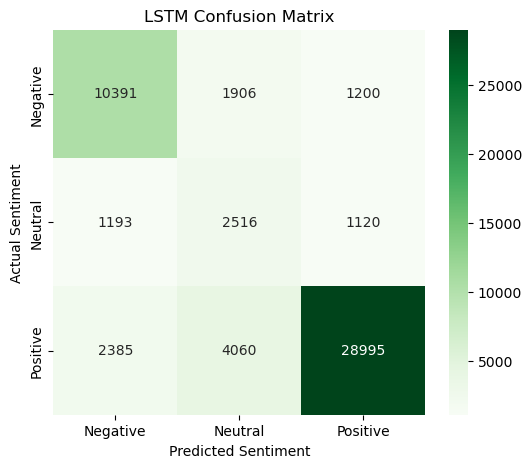

In [29]:
cm_lstm = confusion_matrix(y_test, lstm_pred)

plt.figure(figsize=(6,5))
sns.heatmap(
    cm_lstm,
    annot=True,
    fmt='d',
    cmap='Greens',
    xticklabels=['Negative', 'Neutral', 'Positive'],
    yticklabels=['Negative', 'Neutral', 'Positive']
)

plt.title("LSTM Confusion Matrix")
plt.xlabel("Predicted Sentiment")
plt.ylabel("Actual Sentiment")
plt.show()

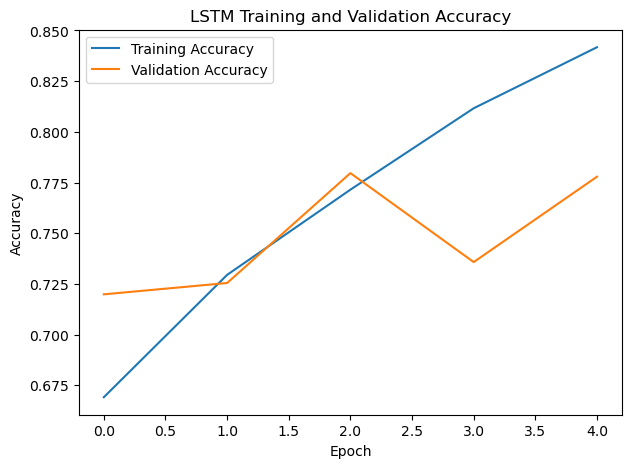

In [30]:
plt.figure(figsize=(7,5))
plt.plot(lstm_history.history['accuracy'], label='Training Accuracy')
plt.plot(lstm_history.history['val_accuracy'], label='Validation Accuracy')
plt.title("LSTM Training and Validation Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.legend()
plt.show()

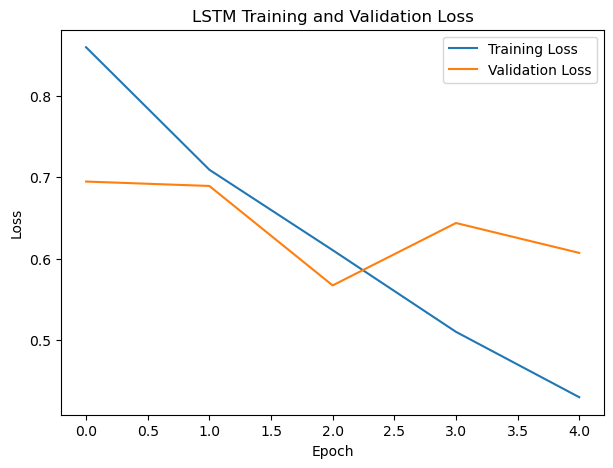

In [31]:
plt.figure(figsize=(7,5))
plt.plot(lstm_history.history['loss'], label='Training Loss')
plt.plot(lstm_history.history['val_loss'], label='Validation Loss')
plt.title("LSTM Training and Validation Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()
plt.show()

In [154]:
# TF-IDF + Logistic Regression Model

start_time = time.time()

tfidf = TfidfVectorizer(
    max_features=20000,
    ngram_range=(1, 2),
    stop_words='english'
)

X_train_tfidf = tfidf.fit_transform(X_train_text)
X_test_tfidf = tfidf.transform(X_test_text)

tfidf_model = LogisticRegression(
    max_iter=1000,
    class_weight='balanced'
)

tfidf_model.fit(X_train_tfidf, y_train)

tfidf_training_time = time.time() - start_time

tfidf_pred = tfidf_model.predict(X_test_tfidf)

# Probability scores required for ROC curve
tfidf_prob = tfidf_model.predict_proba(X_test_tfidf)

tfidf_accuracy = accuracy_score(y_test, tfidf_pred)
tfidf_precision = precision_score(y_test, tfidf_pred, average='weighted',zero_division=0)
tfidf_recall = recall_score(y_test, tfidf_pred, average='weighted',zero_division=0)
tfidf_f1 = f1_score(y_test, tfidf_pred, average='weighted',zero_division=0)

print("TF-IDF Logistic Regression Results")
print("----------------------------------")
print("Accuracy:", tfidf_accuracy)
print("Precision:", tfidf_precision)
print("Recall:", tfidf_recall)
print("F1-score:", tfidf_f1)
print("Training Time:", tfidf_training_time)

TF-IDF Logistic Regression Results
----------------------------------
Accuracy: 0.7470520403228806
Precision: 0.8085698459173645
Recall: 0.7470520403228806
F1-score: 0.7689840863541659
Training Time: 27.667786121368408


In [157]:
print(classification_report(
    y_test,
    tfidf_pred,
    target_names=['Negative', 'Neutral', 'Positive'],
    zero_division=0
))

              precision    recall  f1-score   support

    Negative       0.69      0.74      0.71     13497
     Neutral       0.29      0.57      0.38      4829
    Positive       0.92      0.77      0.84     35440

    accuracy                           0.75     53766
   macro avg       0.63      0.69      0.65     53766
weighted avg       0.81      0.75      0.77     53766



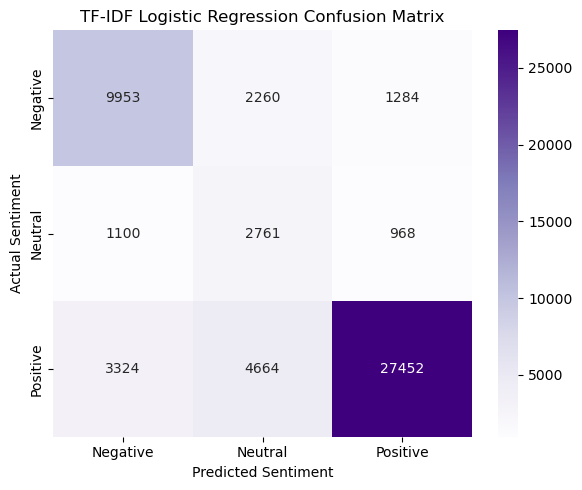

In [34]:
cm_tfidf = confusion_matrix(y_test, tfidf_pred)

plt.figure(figsize=(6,5))
sns.heatmap(
    cm_tfidf,
    annot=True,
    fmt='d',
    cmap='Purples',
    xticklabels=['Negative', 'Neutral', 'Positive'],
    yticklabels=['Negative', 'Neutral', 'Positive']
)

plt.title("TF-IDF Logistic Regression Confusion Matrix")
plt.xlabel("Predicted Sentiment")
plt.ylabel("Actual Sentiment")
plt.tight_layout()
plt.show()

In [80]:
gru_model = Sequential()

gru_model.add(Input(shape=(max_len,)))

gru_model.add(Embedding(
    input_dim=max_words,
    output_dim=128,
    mask_zero=True
))

gru_model.add(GRU(
    units=64,
    return_sequences=False
))

gru_model.add(Dropout(0.5))

gru_model.add(Dense(64, activation='relu'))

gru_model.add(Dropout(0.3))

gru_model.add(Dense(3, activation='softmax'))

gru_model.compile(
    optimizer='adam',
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

gru_model.summary()

Model: "sequential_3"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding_3 (Embedding)         │ (None, 200, 128)       │     2,560,000 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ gru_1 (GRU)                     │ (None, 64)             │        37,248 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_5 (Dropout)             │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_6 (Dense)                 │ (None, 64)             │         4,160 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_6 (Dropout)             │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_7 (Dense)                 │ (None, 3)              │           195 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,601,603 (9.92 MB)

 Trainable params: 2,601,603 (9.92 MB)

 Non-trainable params: 0 (0.00 B)

In [81]:
early_stop = EarlyStopping(
    monitor='val_loss',
    patience=2,
    restore_best_weights=True
)

start_time = time.time()

gru_history = gru_model.fit(
    X_train_pad,
    y_train,
    epochs=10,
    batch_size=64,
    validation_split=0.2,
    callbacks=[early_stop],
    class_weight=class_weights
)

gru_training_time = time.time() - start_time

print("GRU Training Time:", gru_training_time, "seconds")

Epoch 1/10
2017/2017 ━━━━━━━━━━━━━━━━━━━━ 211s 104ms/step - accuracy: 0.6539 - loss: 0.8588 - val_accuracy: 0.7444 - val_loss: 0.6201
Epoch 2/10
2017/2017 ━━━━━━━━━━━━━━━━━━━━ 194s 96ms/step - accuracy: 0.7372 - loss: 0.6870 - val_accuracy: 0.7366 - val_loss: 0.6258
Epoch 3/10
2017/2017 ━━━━━━━━━━━━━━━━━━━━ 190s 94ms/step - accuracy: 0.7880 - loss: 0.5638 - val_accuracy: 0.7820 - val_loss: 0.5504
Epoch 4/10
2017/2017 ━━━━━━━━━━━━━━━━━━━━ 193s 96ms/step - accuracy: 0.8325 - loss: 0.4532 - val_accuracy: 0.7541 - val_loss: 0.6285
Epoch 5/10
2017/2017 ━━━━━━━━━━━━━━━━━━━━ 195s 97ms/step - accuracy: 0.8665 - loss: 0.3606 - val_accuracy: 0.8122 - val_loss: 0.5649
GRU Training Time: 982.851231098175 seconds


In [82]:
gru_loss, gru_accuracy = gru_model.evaluate(X_test_pad, y_test)

print("GRU Test Loss:", gru_loss)
print("GRU Test Accuracy:", gru_accuracy)

1681/1681 ━━━━━━━━━━━━━━━━━━━━ 21s 13ms/step - accuracy: 0.7797 - loss: 0.5530
GRU Test Loss: 0.5529972314834595
GRU Test Accuracy: 0.7797120809555054


In [104]:
gru_pred_prob = gru_model.predict(X_test_pad)
gru_pred = np.argmax(gru_pred_prob, axis=1)

gru_precision = precision_score(y_test, gru_pred, average='weighted', zero_division=0)
gru_recall = recall_score(y_test, gru_pred, average='weighted', zero_division=0)
gru_f1 = f1_score(y_test, gru_pred, average='weighted', zero_division=0)

print("GRU Precision:", gru_precision)
print("GRU Recall:", gru_recall)
print("GRU F1-score:", gru_f1)

print("GRU Prediction Distribution:")
print(np.unique(gru_pred, return_counts=True))


1681/1681 ━━━━━━━━━━━━━━━━━━━━ 21s 12ms/step
GRU Precision: 0.8305206934150859
GRU Recall: 0.7797120857047205
GRU F1-score: 0.799084144029201
GRU Prediction Distribution:
(array([0, 1, 2]), array([13155,  9249, 31362]))


In [109]:
print(classification_report(
    y_test,
    gru_pred,
    target_names=['Negative', 'Neutral', 'Positive'],
    zero_division=0
))

              precision    recall  f1-score   support

    Negative       0.76      0.74      0.75     13497
     Neutral       0.30      0.57      0.39      4829
    Positive       0.93      0.82      0.87     35440

    accuracy                           0.78     53766
   macro avg       0.66      0.71      0.67     53766
weighted avg       0.83      0.78      0.80     53766



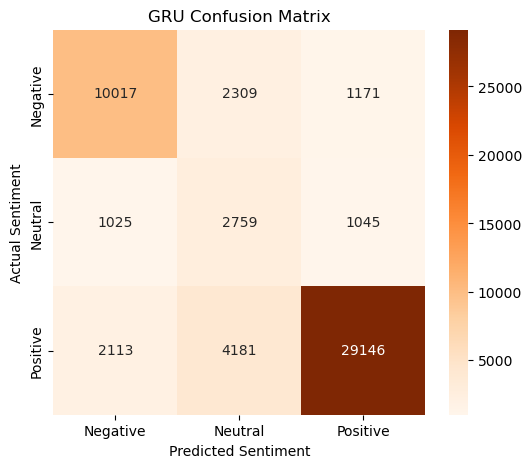

In [105]:
cm_gru = confusion_matrix(y_test, gru_pred)

plt.figure(figsize=(6,5))
sns.heatmap(
    cm_gru,
    annot=True,
    fmt='d',
    cmap='Oranges',
    xticklabels=['Negative', 'Neutral', 'Positive'],
    yticklabels=['Negative', 'Neutral', 'Positive']
)

plt.title("GRU Confusion Matrix")
plt.xlabel("Predicted Sentiment")
plt.ylabel("Actual Sentiment")
plt.show()

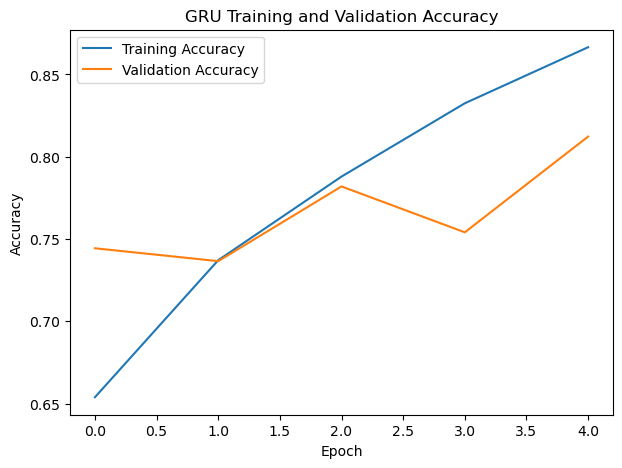

In [87]:
plt.figure(figsize=(7,5))
plt.plot(gru_history.history['accuracy'], label='Training Accuracy')
plt.plot(gru_history.history['val_accuracy'], label='Validation Accuracy')
plt.title("GRU Training and Validation Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.legend()
plt.show()

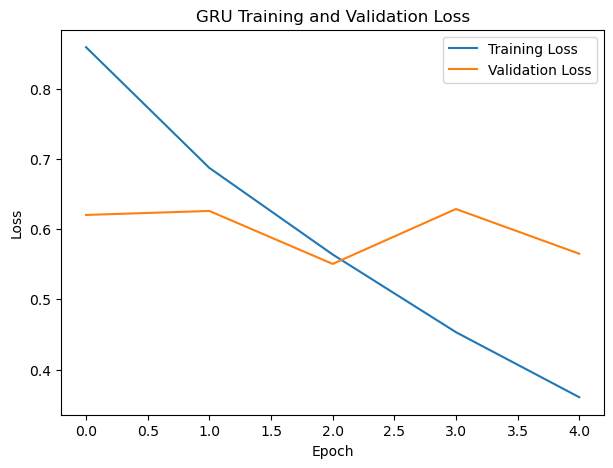

In [88]:
plt.figure(figsize=(7,5))
plt.plot(gru_history.history['loss'], label='Training Loss')
plt.plot(gru_history.history['val_loss'], label='Validation Loss')
plt.title("GRU Training and Validation Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()
plt.show()

In [89]:
bilstm_model = Sequential()

bilstm_model.add(Input(shape=(max_len,)))

bilstm_model.add(Embedding(
    input_dim=max_words,
    output_dim=128,
    mask_zero=True
))

bilstm_model.add(Bidirectional(
    LSTM(
        128,
        dropout=0.2,
        recurrent_dropout=0.2
    )
))

bilstm_model.add(Dense(64, activation='relu'))
bilstm_model.add(Dropout(0.2))

bilstm_model.add(Dense(3, activation='softmax'))

bilstm_model.compile(
    optimizer='adam',
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

bilstm_model.summary()

Model: "sequential_4"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding_4 (Embedding)         │ (None, 200, 128)       │     2,560,000 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ bidirectional_1 (Bidirectional) │ (None, 256)            │       263,168 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_8 (Dense)                 │ (None, 64)             │        16,448 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_7 (Dropout)             │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_9 (Dense)                 │ (None, 3)              │           195 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,839,811 (10.83 MB)

 Trainable params: 2,839,811 (10.83 MB)

 Non-trainable params: 0 (0.00 B)

In [90]:
early_stop = EarlyStopping(
    monitor='val_loss',
    patience=2,
    restore_best_weights=True
)

start_time = time.time()

bilstm_history = bilstm_model.fit(
    X_train_pad,
    y_train,
    epochs=10,
    batch_size=64,
    validation_split=0.2,
    callbacks=[early_stop],
    class_weight=class_weights
)

bilstm_training_time = time.time() - start_time

print("Bi-LSTM Training Time:", bilstm_training_time, "seconds")

Epoch 1/10
2017/2017 ━━━━━━━━━━━━━━━━━━━━ 1388s 687ms/step - accuracy: 0.6597 - loss: 0.8392 - val_accuracy: 0.6918 - val_loss: 0.7422
Epoch 2/10
2017/2017 ━━━━━━━━━━━━━━━━━━━━ 1333s 661ms/step - accuracy: 0.7299 - loss: 0.6892 - val_accuracy: 0.7426 - val_loss: 0.6138
Epoch 3/10
2017/2017 ━━━━━━━━━━━━━━━━━━━━ 1352s 670ms/step - accuracy: 0.7779 - loss: 0.5742 - val_accuracy: 0.7403 - val_loss: 0.6389
Epoch 4/10
2017/2017 ━━━━━━━━━━━━━━━━━━━━ 1404s 696ms/step - accuracy: 0.8169 - loss: 0.4706 - val_accuracy: 0.7361 - val_loss: 0.6471
Bi-LSTM Training Time: 5477.261972904205 seconds


In [91]:
bilstm_loss, bilstm_accuracy = bilstm_model.evaluate(X_test_pad, y_test)

print("Bi-LSTM Test Loss:", bilstm_loss)
print("Bi-LSTM Test Accuracy:", bilstm_accuracy)

1681/1681 ━━━━━━━━━━━━━━━━━━━━ 136s 81ms/step - accuracy: 0.7424 - loss: 0.6114
Bi-LSTM Test Loss: 0.6114019155502319
Bi-LSTM Test Accuracy: 0.7424208521842957


In [112]:
bilstm_pred_prob = bilstm_model.predict(X_test_pad)
bilstm_pred = np.argmax(bilstm_pred_prob, axis=1)

bilstm_precision = precision_score(
    y_test,
    bilstm_pred,
    average='weighted',
    zero_division=0
)

bilstm_recall = recall_score(
    y_test,
    bilstm_pred,
    average='weighted',
    zero_division=0
)

bilstm_f1 = f1_score(
    y_test,
    bilstm_pred,
    average='weighted',
    zero_division=0
)

bilstm_macro_f1 = f1_score(
    y_test,
    bilstm_pred,
    average='macro',
    zero_division=0
)

print("Bi-LSTM Precision:", bilstm_precision)
print("Bi-LSTM Recall:", bilstm_recall)
print("Bi-LSTM Weighted F1-score:", bilstm_f1)
print("Bi-LSTM Macro F1-score:", bilstm_macro_f1)

print("Bi-LSTM Prediction Distribution:")
print(dict(zip(*np.unique(bilstm_pred, return_counts=True))))



1681/1681 ━━━━━━━━━━━━━━━━━━━━ 155s 92ms/step
Bi-LSTM Precision: 0.8226451835341924
Bi-LSTM Recall: 0.7424208607670275
Bi-LSTM Weighted F1-score: 0.7719238553800508
Bi-LSTM Macro F1-score: 0.640119366785241
Bi-LSTM Prediction Distribution:
{np.int64(0): np.int64(12853), np.int64(1): np.int64(11311), np.int64(2): np.int64(29602)}


In [113]:
print(classification_report(
    y_test,
    bilstm_pred,
    target_names=['Negative', 'Neutral', 'Positive'],
    zero_division=0
))

              precision    recall  f1-score   support

    Negative       0.75      0.71      0.73     13497
     Neutral       0.25      0.58      0.35      4829
    Positive       0.93      0.78      0.85     35440

    accuracy                           0.74     53766
   macro avg       0.64      0.69      0.64     53766
weighted avg       0.82      0.74      0.77     53766



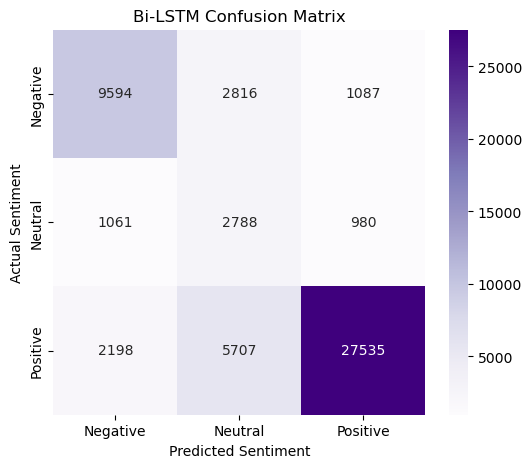

In [115]:
cm_bilstm = confusion_matrix(y_test, bilstm_pred)

plt.figure(figsize=(6,5))
sns.heatmap(
    cm_bilstm,
    annot=True,
    fmt='d',
    cmap='Purples',
    xticklabels=['Negative', 'Neutral', 'Positive'],
    yticklabels=['Negative', 'Neutral', 'Positive']
)

plt.title("Bi-LSTM Confusion Matrix")
plt.xlabel("Predicted Sentiment")
plt.ylabel("Actual Sentiment")
plt.show()

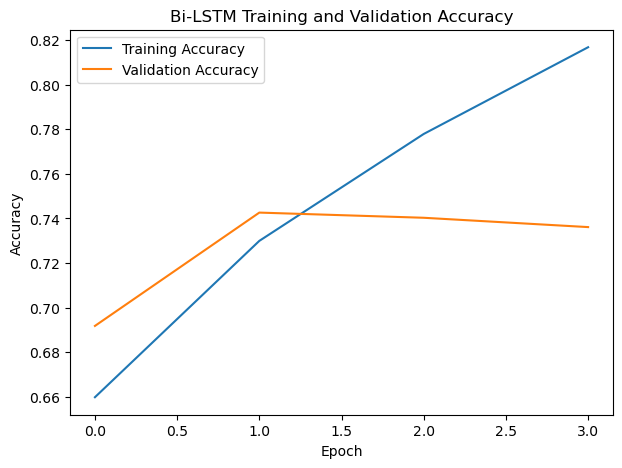

In [94]:
plt.figure(figsize=(7,5))
plt.plot(bilstm_history.history['accuracy'], label='Training Accuracy')
plt.plot(bilstm_history.history['val_accuracy'], label='Validation Accuracy')
plt.title("Bi-LSTM Training and Validation Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.legend()
plt.show()

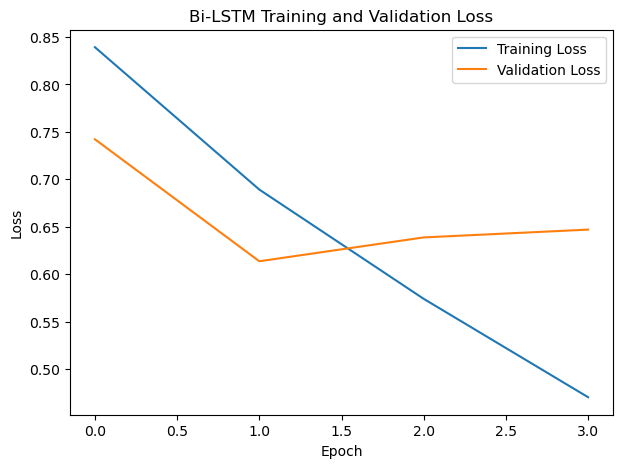

In [95]:
plt.figure(figsize=(7,5))
plt.plot(bilstm_history.history['loss'], label='Training Loss')
plt.plot(bilstm_history.history['val_loss'], label='Validation Loss')
plt.title("Bi-LSTM Training and Validation Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()
plt.show()

In [147]:
def get_micro_roc(y_true_bin, y_score):

    fpr, tpr, _ = roc_curve(
        y_true_bin.ravel(),
        y_score.ravel()
    )

    roc_auc = auc(fpr, tpr)

    return fpr, tpr, roc_auc

In [155]:
tfidf_fpr, tfidf_tpr, tfidf_auc = get_micro_roc(
    y_test_bin,
    tfidf_prob
)

lstm_fpr, lstm_tpr, lstm_auc = get_micro_roc(
    y_test_bin,
    lstm_pred_prob
)

gru_fpr, gru_tpr, gru_auc = get_micro_roc(
    y_test_bin,
    gru_pred_prob
)

bilstm_fpr, bilstm_tpr, bilstm_auc = get_micro_roc(
    y_test_bin,
    bilstm_pred_prob
)

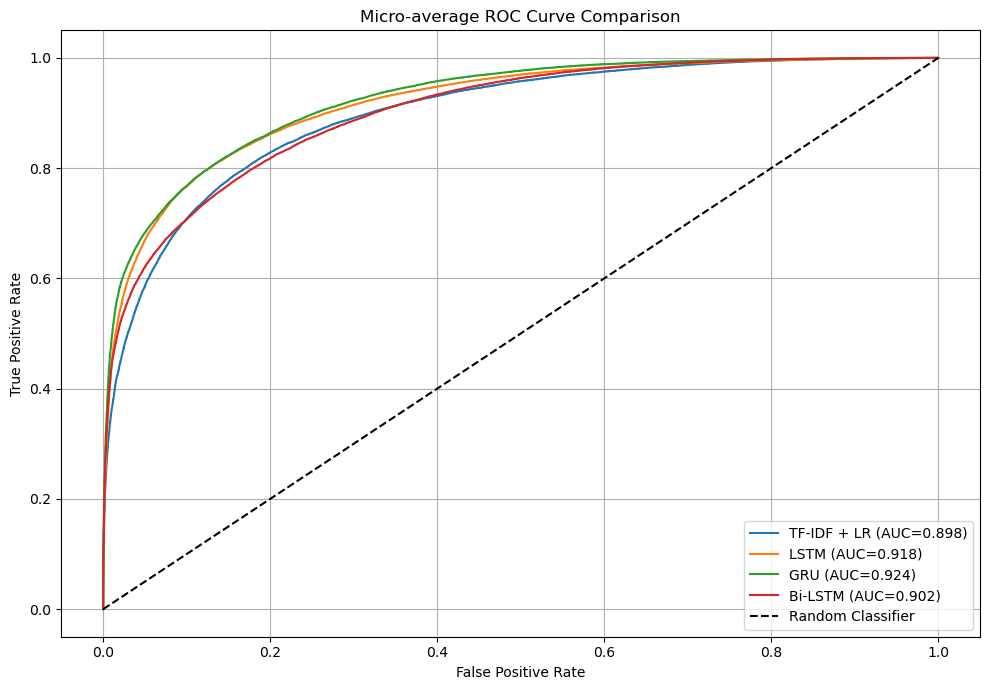

In [156]:
plt.figure(figsize=(10,7))

plt.plot(
    tfidf_fpr,
    tfidf_tpr,
    label=f"TF-IDF + LR (AUC={tfidf_auc:.3f})"
)

plt.plot(
    lstm_fpr,
    lstm_tpr,
    label=f"LSTM (AUC={lstm_auc:.3f})"
)

plt.plot(
    gru_fpr,
    gru_tpr,
    label=f"GRU (AUC={gru_auc:.3f})"
)

plt.plot(
    bilstm_fpr,
    bilstm_tpr,
    label=f"Bi-LSTM (AUC={bilstm_auc:.3f})"
)

plt.plot(
    [0,1],
    [0,1],
    linestyle='--',
    color='black',
    label='Random Classifier'
)

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("Micro-average ROC Curve Comparison")

plt.legend()

plt.grid(True)

plt.tight_layout()

plt.show()

In [96]:
# Final Model Comparison Table

results = []

# VADER Results
# VADER is rule-based, so training time is 0
vader_training_time = 0

results.append({
    'Model': 'VADER',
    'Accuracy': vader_accuracy,
    'Precision': vader_precision,
    'Recall': vader_recall,
    'F1-score': vader_f1,
    'Training Time (seconds)': vader_training_time
})

# TF-IDF Results
results.append({
    'Model': 'TF-IDF + Logistic Regression',
    'Accuracy': tfidf_accuracy,
    'Precision': tfidf_precision,
    'Recall': tfidf_recall,
    'F1-score': tfidf_f1,
    'Training Time (seconds)': tfidf_training_time
})

# LSTM Results
results.append({
    'Model': 'LSTM',
    'Accuracy': lstm_accuracy,
    'Precision': lstm_precision,
    'Recall': lstm_recall,
    'F1-score': lstm_f1,
    'Training Time (seconds)': lstm_training_time
})

# GRU Results
results.append({
    'Model': 'GRU',
    'Accuracy': gru_accuracy,
    'Precision': gru_precision,
    'Recall': gru_recall,
    'F1-score': gru_f1,
    'Training Time (seconds)': gru_training_time
})

# Bi-LSTM Results
results.append({
    'Model': 'Bi-LSTM',
    'Accuracy': bilstm_accuracy,
    'Precision': bilstm_precision,
    'Recall': bilstm_recall,
    'F1-score': bilstm_f1,
    'Training Time (seconds)': bilstm_training_time
})


# Create dataframe
results_df = pd.DataFrame(results)

# Convert metrics to percentage
results_df[['Accuracy', 'Precision', 'Recall', 'F1-score']] = (
    results_df[['Accuracy', 'Precision', 'Recall', 'F1-score']] * 100
).round(2)

# Round training time
results_df['Training Time (seconds)'] = (
    results_df['Training Time (seconds)']
).round(2)

# Sort models by performance
results_df = results_df.sort_values(
    by=['Accuracy', 'F1-score'],
    ascending=False
).reset_index(drop=True)

results_df

,Model,Accuracy,Precision,Recall,F1-score,Training Time (seconds)
0,GRU,77.97,83.05,77.97,79.91,982.85
1,LSTM,77.93,82.37,77.93,79.65,925.07
2,TF-IDF + Logistic Regression,74.71,80.86,74.71,76.90,26.56
3,Bi-LSTM,74.24,82.26,74.24,77.19,5477.26
4,VADER,54.45,62.37,54.45,55.30,0.00


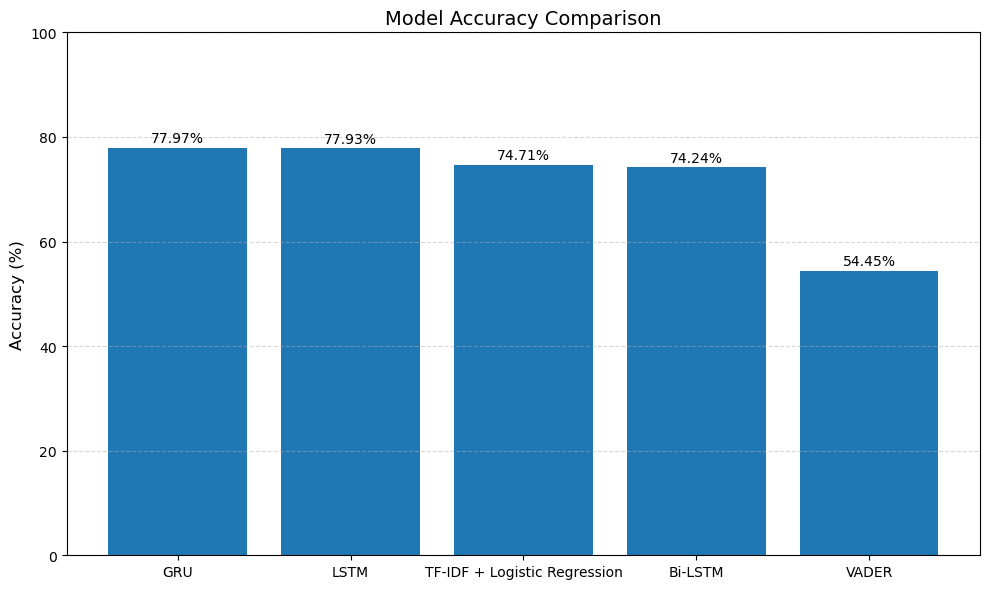

In [132]:
plt.figure(figsize=(10,6))

bars = plt.bar(
    results_df['Model'],
    results_df['Accuracy']
)

plt.title("Model Accuracy Comparison", fontsize=14)
plt.xlabel("", fontsize=12)
plt.ylabel("Accuracy (%)", fontsize=12)

# Since Accuracy is now in percentages
plt.ylim(0, 100)

# Display accuracy value on top of each bar
for bar in bars:
    height = bar.get_height()
    plt.text(
        bar.get_x() + bar.get_width()/2,
        height + 1,
        f"{height:.2f}%",
        ha='center',
        fontsize=10
    )

plt.grid(axis='y', linestyle='--', alpha=0.5)

plt.tight_layout()
plt.show()

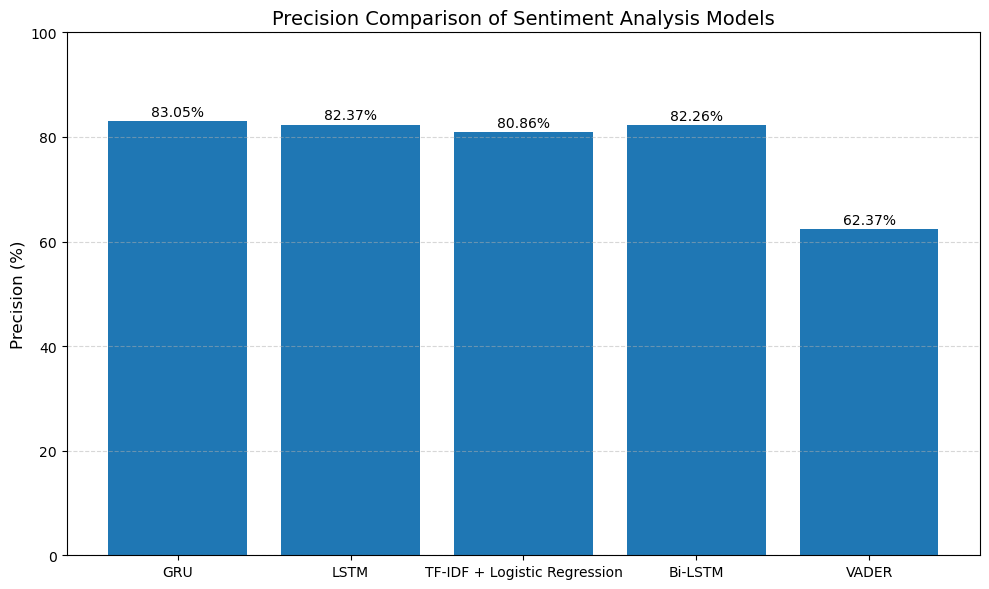

In [133]:
plt.figure(figsize=(10,6))

bars = plt.bar(
    results_df['Model'],
    results_df['Precision']
)

plt.title("Precision Comparison of Sentiment Analysis Models", fontsize=14)
plt.xlabel("", fontsize=12)
plt.ylabel("Precision (%)", fontsize=12)

plt.ylim(0, 100)

# Display precision values on top of each bar
for bar in bars:
    height = bar.get_height()
    plt.text(
        bar.get_x() + bar.get_width()/2,
        height + 1,
        f"{height:.2f}%",
        ha='center',
        fontsize=10
    )

plt.grid(axis='y', linestyle='--', alpha=0.5)

plt.tight_layout()
plt.show()

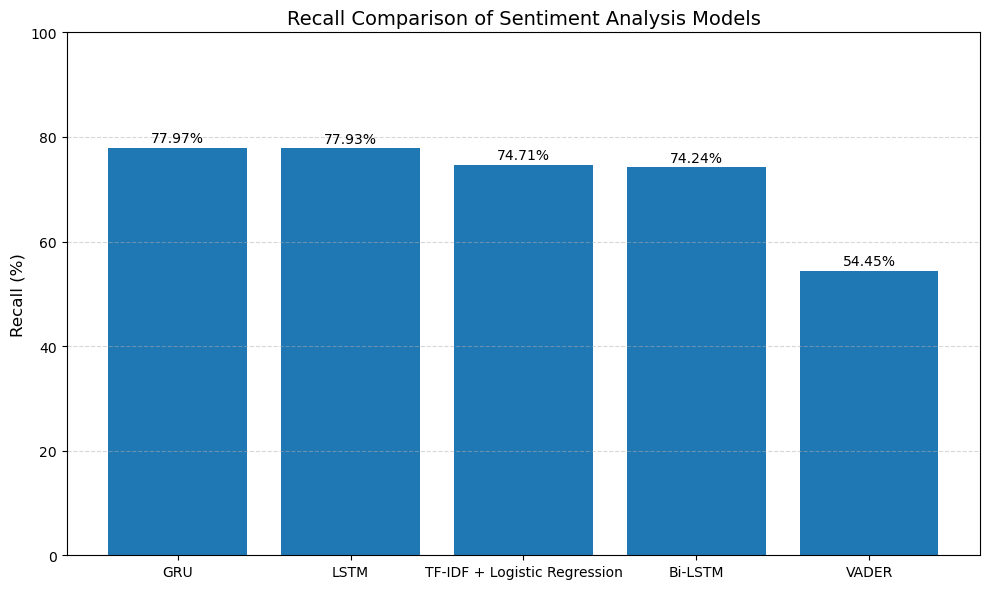

In [126]:
plt.figure(figsize=(10,6))

bars = plt.bar(
    results_df['Model'],
    results_df['Recall']
)

plt.title("Recall Comparison of Sentiment Analysis Models", fontsize=14)
plt.xlabel("", fontsize=12)
plt.ylabel("Recall (%)", fontsize=12)

plt.ylim(0, 100)

# Display recall value on top of each bar
for bar in bars:
    height = bar.get_height()
    plt.text(
        bar.get_x() + bar.get_width()/2,
        height + 1,
        f"{height:.2f}%",
        ha='center',
        fontsize=10
    )

plt.grid(axis='y', linestyle='--', alpha=0.5)

plt.tight_layout()
plt.show()

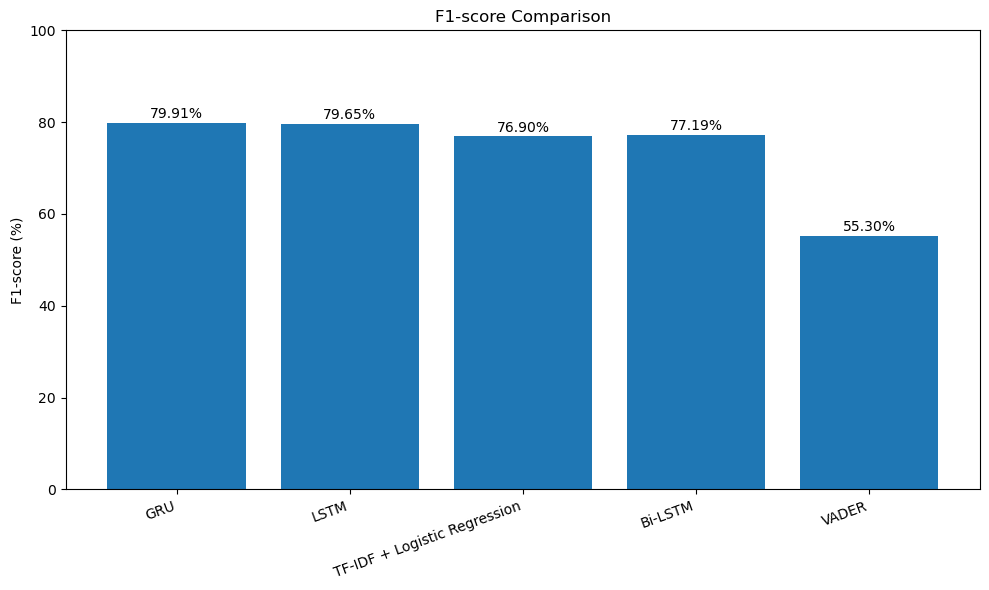

In [137]:
plt.figure(figsize=(10,6))

bars = plt.bar(results_df['Model'], results_df['F1-score'])
plt.title("F1-score Comparison")
plt.ylabel("F1-score (%)")
plt.ylim(0,100)

for bar in bars:
    height = bar.get_height()
    plt.text(
        bar.get_x() + bar.get_width()/2,
        height + 1,
        f"{height:.2f}%",
        ha='center',
        fontsize=10
    )

plt.xticks(rotation=20, ha='right')   # <-- Fix

plt.tight_layout()
plt.show()

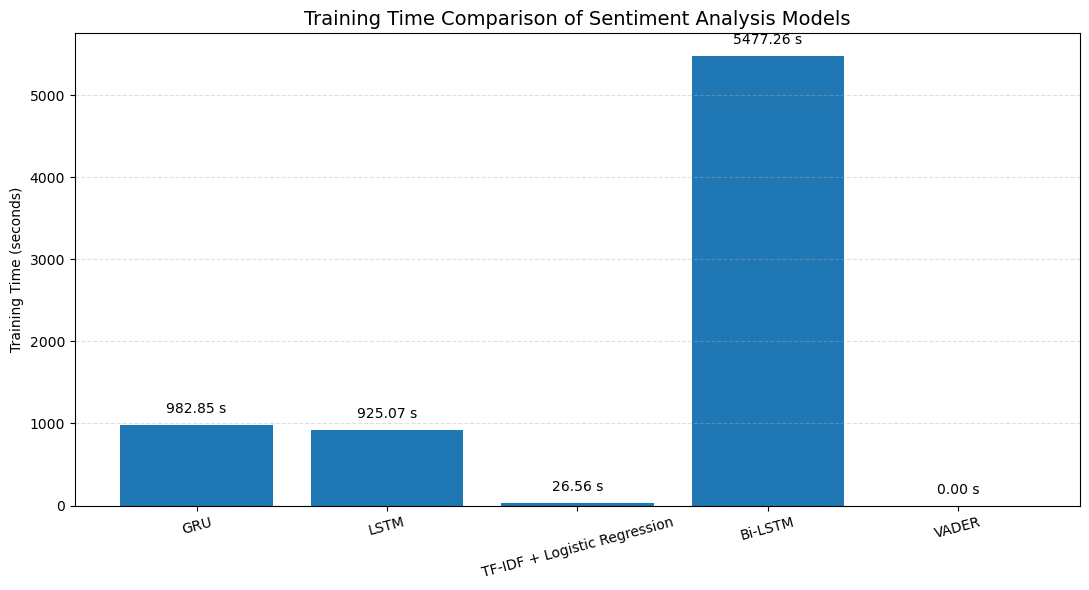

In [138]:
plt.figure(figsize=(11,6))

bars = plt.bar(
    results_df['Model'],
    results_df['Training Time (seconds)']
)

plt.title("Training Time Comparison of Sentiment Analysis Models", fontsize=14)
plt.xlabel("")
plt.ylabel("Training Time (seconds)")

# Add value labels
for bar in bars:
    height = bar.get_height()
    plt.text(
        bar.get_x() + bar.get_width()/2,
        height + (max(results_df['Training Time (seconds)']) * 0.02),
        f"{height:.2f} s",
        ha='center',
        va='bottom',
        fontsize=10,
        #fontweight='bold'
    )

plt.xticks(rotation=15)
plt.grid(axis='y', linestyle='--', alpha=0.4)
plt.tight_layout()
plt.show()


In [135]:
results_df.sort_values(
    by="Accuracy",
    ascending=False
)

,Model,Accuracy,Precision,Recall,F1-score,Training Time (seconds)
0,GRU,77.97,83.05,77.97,79.91,982.85
1,LSTM,77.93,82.37,77.93,79.65,925.07
2,TF-IDF + Logistic Regression,74.71,80.86,74.71,76.90,26.56
3,Bi-LSTM,74.24,82.26,74.24,77.19,5477.26
4,VADER,54.45,62.37,54.45,55.30,0.00
